# 05 · 媒资管理与 Nacos Gateway MinIO


## 资料来源与当天目标

本篇对应 14 天规划的 **day05 媒资管理 Nacos Gateway MinIO**。前四天围绕内容管理服务开发；第五天新增媒资服务，把各服务接入服务注册与配置中心，通过网关统一入口，再完成课程图片上传。

| 原始资料 | 本篇使用范围 |
|---|---|
| day05 / 资料 /《第3章媒资管理模块v3.1.docx》 | 第 1—4 节：业务与数据模型、Nacos、Gateway、媒资工程、分布式存储、MinIO SDK、上传图片与事务优化 |
| day05 / 代码 /`xuecheng-plus-project.zip` | 静态核对 16 个 POM、各服务 bootstrap、网关、媒资 Controller / Service / DTO / PO 与 HTTP 示例 |
| day05 / 资料 /`xuecheng-plus-media.zip` | 媒资模块基础骨架，共 4 个 POM；与完整项目包的媒资实现不同 |
| day05 / 资料 /`nacos配置/nacos_config_export.zip` | 20 个 YAML 配置，包含本日服务及后续章节配置；核对 Data ID、分组、路由、数据库和 MinIO 配置 |
| day05 / 资料 /`xcplus_media.sql` | 静态核对媒资表、处理任务表、消息表结构与索引，没有执行导入 |
| [百度网盘分享](https://pan.baidu.com/s/16iXzw7cFDk3FqG9DfPqbdg?pwd=6633) | 提取码 `6633`；Java 项目《学成在线》企业级开发实战 → 学成在线项目—资料 → day05 |

**当天成果**：理解上传文件与保存课程的两次请求；知道文件内容和元信息分别存在哪里；服务通过 Nacos 注册与读配置；Gateway 保留业务路径转发；图片写入 MinIO、元信息入库并返回 URL。

> 本篇全部为 Markdown 单元，原图嵌入 Notebook。原资料、源码事实和“补充 / 校正”分别说明。Java、YAML、HTTP 是复现与学习示例，未启动课程环境、执行 SQL、上传文件或编译项目。第 5 节断点续传及 XXL-JOB 随 day06 展开，视频处理随 day07 展开。


## 1. 媒资管理：管理文件，也管理使用文件的过程

媒资管理是 `Media Asset Management`，即媒体资源管理。教学机构不仅需要一个“放视频的目录”，还需要按名称查资源、记录上传者与所属机构、处理视频、审核资源，并把资源关联到课程计划。

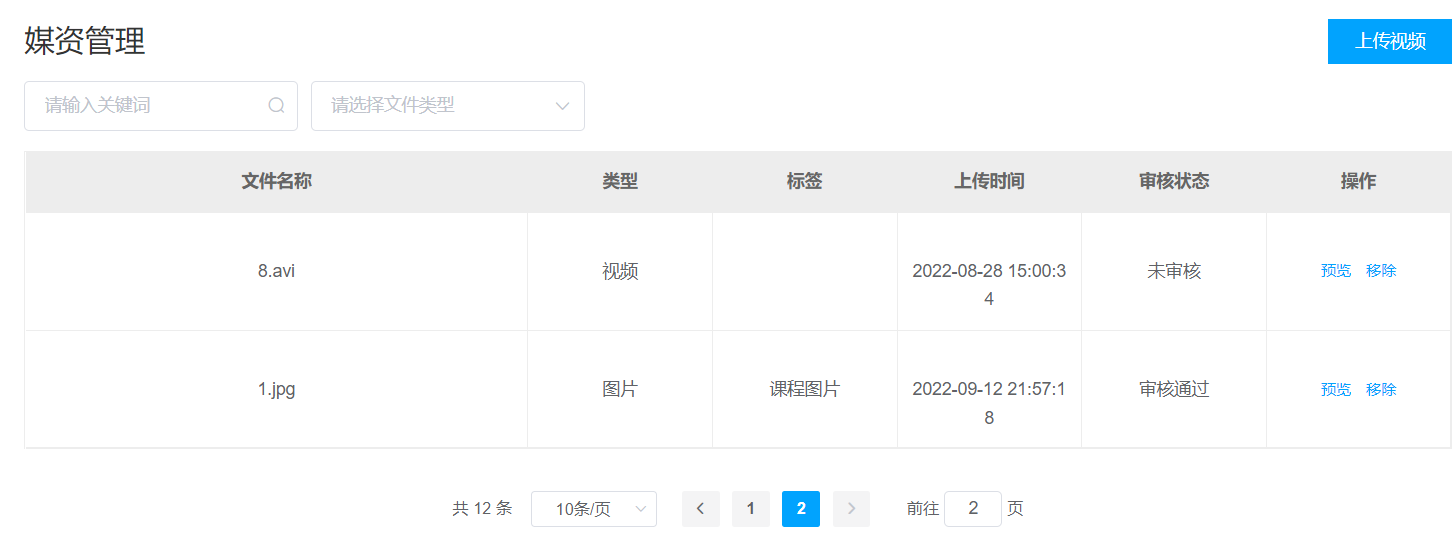

| 能力 | 解决的问题 | 本日深度 |
|---|---|---|
| 查询媒资 | 找到本机构的图片、视频、文档 | 读取现有分页骨架，补充筛选与归属条件 |
| 上传图片 / 普通文件 | 保存课程封面等小文件 | 本日实现主体 |
| 上传视频 | 大文件中断后能继续上传 | 理解需求，下一篇实现断点续传 |
| 视频处理 | 将原始视频转成适合播放的格式 | 后续后台任务与视频处理 |
| 审核 | 确认媒资是否允许使用 | 业务介绍，本日没有完成审核接口 |
| 绑定媒资 | 课程小节选择已上传资源 | 理解与内容服务的关系，后续实现 |

“上传成功”“处理成功”“审核通过”“绑定到课程”是不同阶段。上传接口返回文件 URL，不意味着视频已经转码、审核并可以学习。

讲义还介绍自动审核和人工审核，这是平台业务范围；不能因为出现了审核页面，就认为 day05 包已实现整套审核流程。


## 2. 上传课程图片：两次请求和三个保存位置

为什么图片上传后还要点击“保存课程”？因为媒资服务负责保存资源，内容服务负责保存课程与该资源的关系。

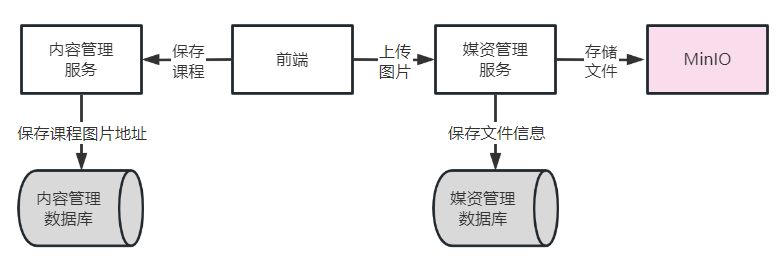

完整流程：

1. 用户在课程编辑页面选择图片，前端向媒资服务发 multipart 请求。
2. 媒资服务把文件内容写入 MinIO。
3. 媒资服务把文件元信息写入媒资库 `media_files`，返回文件信息与 `url`。
4. 前端将返回的 URL 放到课程表单的 `pic` 字段。
5. 前端向内容服务新增 / 修改课程，内容库 `course_base.pic` 保存该 URL。

| 保存位置 | 保存的内容 |
|---|---|
| MinIO 对象 | 图片字节，例如 PNG / JPEG 文件内容 |
| 媒资库 `media_files` | 文件标识、原名称、桶、对象路径、大小、机构、URL |
| 内容库 `course_base.pic` | 课程封面引用 |

如果只完成前三步，媒资列表可能看到图片，但课程刷新后没有封面，因为课程还没保存。如果只改 `pic` 而 URL 指向不存在的对象，数据库有地址也显示不出图片。

**验收思路**：同时确认 MinIO 对象、媒资记录、课程 `pic`，并重新进入课程编辑页查看回显。


## 3. 数据模型：文件内容与业务元信息分开

本日最重要的表是 `media_files`。它不保存整个图片 / 视频二进制，而是保存资源定位和业务管理信息。

| 字段 | Java 类型 / 数据库作用 |
|---|---|
| `id` | String；数据库 `varchar(32)` 主键，当前上传代码显式设置文件 MD5 |
| `fileId` | String；对应 `file_id`，数据库有唯一索引 |
| `companyId` | Long；资源所属机构 |
| `filename` | String；用户原文件名，用于展示 |
| `fileType` | String；本日图片使用 `001001` |
| `bucket` | String；存储桶名，如 `mediafiles` |
| `filePath` | String；桶内对象名，如 `2026/10/10/xxx.png` |
| `url` | String；当前实现返回 `/mediafiles/2026/10/10/xxx.png` |
| `fileSize` | Long；文件字节数 |
| `createDate` | LocalDateTime；上传时间 |
| `status / auditStatus` | String；资源状态与审核状态，不能混为一个字段 |

原 PO 的主键注解是 `IdType.ASSIGN_ID`，但上传方法主动设置 `id = fileMd5`，不会在该路径上再生成一个雪花 ID。SQL 示例也存在历史 ID 与 `file_id` 不同的记录，不能假设全库所有历史数据都满足 `id == MD5`。

其他相关表：

- `media_process`：待处理视频任务。
- `media_process_history`：处理完成后的历史记录。
- `teachplan_media`：课程计划与媒资的绑定，属于内容管理模块。
- SQL 包另有 `mq_message` 与 `mq_message_history`；出现表不等于本日已完成消息流程。

**资料差异**：SQL 将 `media_files.status` 注释为“1 正常、0 不展示”，PO 注释为“1 未处理、2 处理完成”。本日图片保存实际设置 `status="1"`、`auditStatus="002003"`；具体含义应以实际字典与业务约定统一，不能套用 `media_process.status` 的处理状态解释所有表。


## 4. 媒资工程、代码版本与数据库准备

媒资模块延续内容管理的分层方式：`api → service → model`，Mapper 位于 service，通用分页与异常来自 `xuecheng-plus-base`。

| 工程 | 主要职责 |
|---|---|
| `xuecheng-plus-media` | 媒资父模块，聚合 API、Service、Model |
| `xuecheng-plus-media-api` | Controller、Spring Boot 启动类、HTTP 入口 |
| `xuecheng-plus-media-service` | 查询、MinIO 上传、元信息保存、Mapper |
| `xuecheng-plus-media-model` | PO 与查询 / 上传 DTO |
| `xuecheng-plus-gateway` | 独立网关应用，统一转发请求 |

课程步骤是把媒资模块拷入项目目录，并将 POM 导入 Maven。本次仅提取源码阅读，没有改动用户课程工程。

**两个代码包的区别**：资料中的 69KB 媒资包只有列表分页骨架；代码目录中的完整项目包已包含 MinIO 配置、图片上传 DTO、Controller 与 Service，并采用代理调用元信息事务方法。不能把基础骨架当作完整上传实现。

数据库名称有三种历史写法：讲义要求创建 `xc_media`，配置包的 JDBC URL 使用 `xcplus_media`，SQL 文件头记录原导出库 `xc148_media`。SQL 文件名不决定导入目标库；应选定自己的目标库，把 JDBC URL 与导入位置统一，再检查表是否存在。

已核对版本：Java `1.8`，Spring Boot `2.3.7.RELEASE`，Spring Cloud `Hoxton.SR9`，Spring Cloud Alibaba `2.2.6.RELEASE`，MyBatis-Plus `3.4.1`，MySQL Connector `8.0.30`，Swagger Starter `1.9.0.RELEASE`。上传使用 MinIO Java SDK `8.4.3`、OkHttp `4.8.1`、SimpleMagic `1.17`、Commons Codec `1.11`。


## 5. 媒资列表查询：已有分页，条件仍需补全

源码接口为 `POST /media/files`；页码与大小从请求参数绑定 `PageParams`，JSON 绑定 `QueryMediaParamsDto`，返回 `PageResult<MediaFiles>`。

查询 DTO 有 `filename`、`fileType`、`auditStatus`。Controller 传入临时机构 `1232141425L`，但完整项目与基础媒资包的 `queryMediaFiels` 都只创建空 `LambdaQueryWrapper`，没有使用机构或筛选字段。

**补充查询条件片段**，放到分页查询前：

```java
if (companyId == null) {
    throw new XueChengPlusException("机构ID不能为空");
}
QueryMediaParamsDto params = queryMediaParamsDto == null
    ? new QueryMediaParamsDto() : queryMediaParamsDto;
LambdaQueryWrapper<MediaFiles> queryWrapper = new LambdaQueryWrapper<>();
queryWrapper.eq(MediaFiles::getCompanyId, companyId)
    .like(StringUtils.isNotBlank(params.getFilename()),
          MediaFiles::getFilename, params.getFilename())
    .eq(StringUtils.isNotBlank(params.getFileType()),
        MediaFiles::getFileType, params.getFileType())
    .eq(StringUtils.isNotBlank(params.getAuditStatus()),
        MediaFiles::getAuditStatus, params.getAuditStatus())
    .orderByDesc(MediaFiles::getCreateDate)
    .orderByDesc(MediaFiles::getId);
```

这里使用 `org.apache.commons.lang3.StringUtils`；机构条件始终加，其他条件非空时加。按创建时间和 ID 排序是本篇补充的稳定分页策略。

`queryMediaFiels` 是源码保留的拼写，接口与实现目前一致。若重命名为 `queryMediaFiles`，要同步修改全部引用，不能只修改实现类。

页码至少为 1、页大小设置合理上限；身份接入后机构来自认证上下文。页面传 `companyId` 不能取代可信的归属条件。


## 6. 为什么引入 Gateway 和 Nacos

前几天前端分别请求内容服务、系统服务；随着媒资等服务增加，前端记住每个服务地址会越来越难维护。服务扩容或地址改变，也不应该要求每个页面都重写 URL。

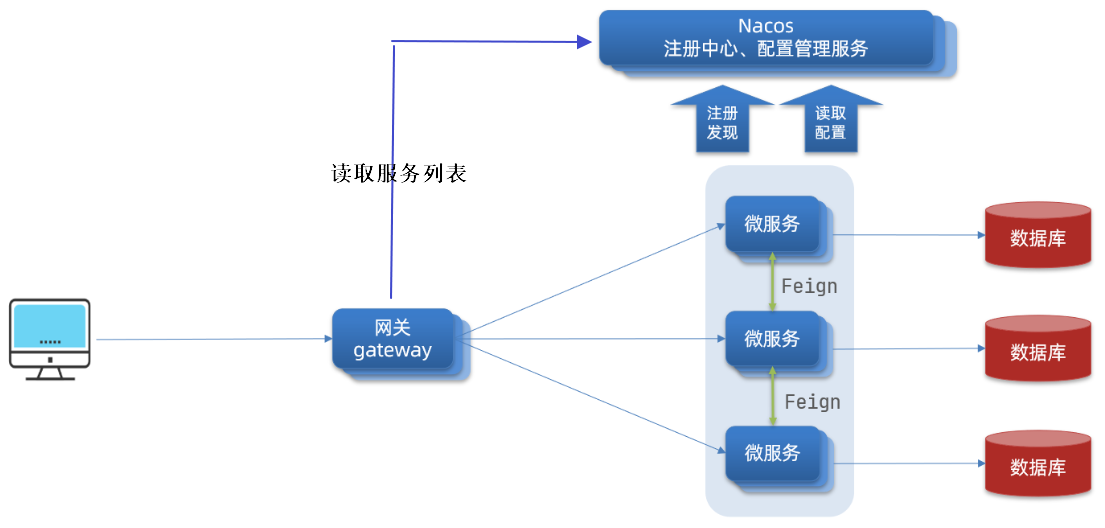

| 组件 | 负责什么 |
|---|---|
| Gateway | 接收请求，按路由规则选择目标服务并转发 |
| Nacos 服务发现 | 保存服务名与实例地址，供客户端发现服务 |
| Nacos 配置中心 | 集中管理应用配置并支持配置变化通知 |
| 业务服务 | 执行课程、系统或媒资业务 |

运行过程：业务服务向 Nacos 注册 → Gateway 发现服务实例 → 前端请求 Gateway → 路由匹配服务 → 转发给某个可用实例。

**概念区分**：Gateway 转发业务流量；Nacos提供服务与配置信息。请求不是先经过 Nacos 再到业务服务。Nacos 自身不是图片存储系统，文件内容仍在 MinIO。

网关也可以承载认证、限流等能力，但创建一个 Gateway 工程并不会自动实现这些业务策略，本日重点是入口与路由。


## 7. Nacos 服务注册：依赖、服务名与实例地址

注册发现依赖为 `spring-cloud-starter-alibaba-nacos-discovery`，版本由父工程的 Spring Cloud Alibaba BOM 管理。

```xml
<dependency>
    <groupId>com.alibaba.cloud</groupId>
    <artifactId>spring-cloud-starter-alibaba-nacos-discovery</artifactId>
</dependency>
```

以媒资 API 为例，注册配置如下；`dev402` 来自 day05 完整代码的 bootstrap，不是讲义统一演示的 `dev`。

```yaml
spring:
  application:
    name: media-api
  cloud:
    nacos:
      server-addr: 192.168.101.65:8848
      discovery:
        namespace: dev402
        group: xuecheng-plus-project
```

`spring.application.name` 是实例注册的服务名，网关 `lb://media-api` 必须与它一致。注册成功还要确认实例的 IP / 端口可被网关访问；注册了 `localhost` 或错误网卡地址，也可能无法正常转发。

讲义 Nacos 控制台地址是 `http://192.168.101.65:8848/nacos/`。IP 是课程虚拟机示例，复现时替换为自己的环境；笔记没有访问或启动这台课程虚拟机。


## 8. namespace 与 group：隔离环境和项目

讲义把 namespace 用于环境隔离，把 group 用于项目区分。它们是隔离维度，实际组织方式可以按团队设计。

| 维度 | 示例 | 注意点 |
|---|---|---|
| namespace | 开发、测试、生产；班级 `dev402` | 客户端填命名空间 ID，不能只凭界面显示名称猜值 |
| discovery group | `xuecheng-plus-project` | 网关与目标服务应在可见的同一分组 |
| config group | `xuecheng-plus-project` | 应用配置文件所在分组 |
| 公共配置 group | `xuecheng-plus-common` | swagger、logging 等共享配置，可单独指定 |

注册发现与配置中心各有 namespace / group 字段：

`spring.cloud.nacos.discovery.*` 管服务实例；`spring.cloud.nacos.config.*` 管配置读取。只改其中一套，可能出现“读到配置却找不到服务”或“注册成功但读不到数据库配置”。

**场景**：媒资服务注册到 `dev402`，网关却查 `dev`，即使服务名都是 `media-api`，网关也未必能发现实例。排错要核对地址、命名空间 ID、分组、服务名和健康实例，不只核对端口。

命名空间名和 `spring.profiles.active=dev` 也不是同一件事：前者决定在哪个隔离空间找配置，后者参与应用配置 Data ID 的生成。


## 9. 配置三要素：怎样找到一个 YAML 文件

一个 Nacos 配置由 **namespace + group + Data ID** 定位。相同 Data ID 在不同环境 / 分组可以保存不同内容。

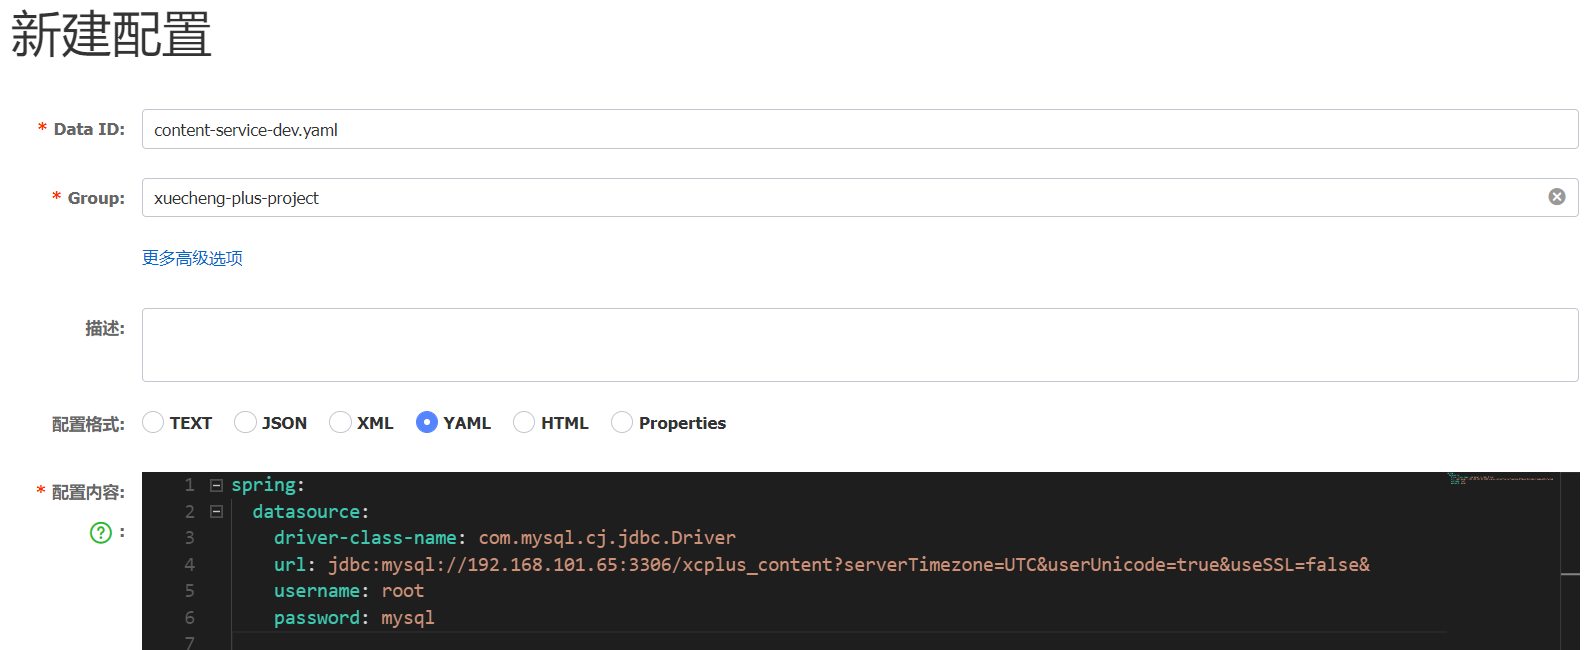

应用配置的课程命名规则是：

```text
应用名 - profile . 文件后缀
media-api-dev.yaml
content-service-dev.yaml
gateway-dev.yaml
```

| 部分 | 来自哪里 |
|---|---|
| `media-api` | 本地 `spring.application.name` |
| `dev` | `spring.profiles.active` |
| `yaml` | `spring.cloud.nacos.config.file-extension` |

`media-api-dev.yaml` 与 `media-api-dev.yml` 是两个不同 Data ID；本地配置文件叫 `bootstrap.yml` 不妨碍远端 Data ID 使用 `.yaml`。

这是课程自动加载应用配置的命名方式，**不是 Nacos 要求所有文件都必须这样命名**。`extension-configs`、`shared-configs` 可以通过明确的 `data-id` 引用其他文件。

应用名、Nacos 地址等启动定位信息要先放在本地。若把应用名只放到还未定位的远端文件中，会出现“得先读到文件才能知道该读哪个文件”的问题。


## 10. bootstrap：先定位配置，再启动业务

课程使用 Spring Boot 2.3 与 Spring Cloud Hoxton 的 bootstrap 方式。不要直接搬用新版本的 `spring.config.import` 配置并假设行为相同。

day05 完整包的 `media-api/src/main/resources/bootstrap.yml` 包含下列配置：

```yaml
spring:
  application:
    name: media-api
  cloud:
    nacos:
      server-addr: 192.168.101.65:8848
      discovery:
        namespace: dev402
        group: xuecheng-plus-project
      config:
        namespace: dev402
        group: xuecheng-plus-project
        file-extension: yaml
        refresh-enabled: true
        extension-configs:
          - data-id: media-service-${spring.profiles.active}.yaml
            group: xuecheng-plus-project
            refresh: true
        shared-configs:
          - data-id: swagger-${spring.profiles.active}.yaml
            group: xuecheng-plus-common
            refresh: true
          - data-id: logging-${spring.profiles.active}.yaml
            group: xuecheng-plus-common
            refresh: true
  profiles:
    active: dev
```

结果是：应用配置 `media-api-dev.yaml`，扩展配置 `media-service-dev.yaml`，共享配置 `swagger-dev.yaml` 与 `logging-dev.yaml`。都应位于实际选择的命名空间内。

API 工程依赖 Service 的 JAR，但这个 JAR 不代表另启动一个 `media-service` 服务。API 应用通过扩展配置显式取得 Service 所需的数据源、MinIO 等配置。

配置中心 Starter 为 `spring-cloud-starter-alibaba-nacos-config`。只有 discovery 依赖负责注册，并不会同时自动启用配置读取；各工程 POM 应按用途核对。


## 11. 应用、扩展与共享配置各放什么

把所有配置都塞进一个文件会难以复用，也容易让网关误加载业务数据库配置。课程按职责拆分文件：

| 配置 | 典型内容 | 引入方式 |
|---|---|---|
| `media-api-dev.yaml` | 端口 63050、`context-path=/media` | 应用名自动定位 |
| `media-service-dev.yaml` | 数据源、MinIO 桶和连接信息 | `extension-configs` |
| `swagger-dev.yaml` | 文档基础配置 | `shared-configs`，公共分组 |
| `logging-dev.yaml` | `logging.config` 等日志配置 | `shared-configs`，公共分组 |
| `gateway-dev.yaml` | 端口 63010 与路由 | 网关应用名自动定位 |

API 远端配置的本日核心：

```yaml
server:
  port: 63050
  servlet:
    context-path: /media
```

以下是**参数化的 Service 配置示例**。与原配置包字段一致，用环境变量提供连接凭据；目标库使用配置包中的 `xcplus_media`，可按自己选定的库修改。

```yaml
spring:
  datasource:
    driver-class-name: com.mysql.cj.jdbc.Driver
    url: jdbc:mysql://192.168.101.65:3306/xcplus_media?serverTimezone=UTC
    username: ${MEDIA_DB_USERNAME}
    password: ${MEDIA_DB_PASSWORD}
minio:
  endpoint: http://192.168.101.65:9000
  accessKey: ${MINIO_ACCESS_KEY}
  secretKey: ${MINIO_SECRET_KEY}
  bucket:
    files: mediafiles
    videofiles: video
```

示例要求运行环境提供对应变量，不提供就不能照抄启动。客户端的 `accessKey / secretKey` 是 SDK 凭据；服务器进程配置根账号的 `MINIO_ROOT_USER / MINIO_ROOT_PASSWORD` 是另一组参数名。

配置包的媒资 Service 文件还含 XXL-JOB 与 FFmpeg 配置，这些属于后续章节。读到它们不等于 day05 已经实现后台视频任务。


## 12. 配置优先级与刷新：不能只背一句顺序

讲义给出“应用配置 > 扩展配置 > 共享配置 > 本地配置”的顺序。对当前 Nacos 客户端，先理解远端几类配置之间的覆盖关系：应用配置通常高于扩展配置，扩展高于共享；同一类列表还要考虑加载顺序。

但“远端与本地、环境变量、JVM 参数谁优先”还涉及 Spring Cloud 的属性源插入与覆盖设置，不能把讲义顺序当作所有 Spring Boot 版本、所有启动方式的固定规则。

| 问题 | 核对方向 |
|---|---|
| 改本地 `server.port` 仍使用 63040 | 远端应用配置是否有同名值，覆盖策略是什么 |
| 扩展文件的数据源没加载 | Data ID、分组、命名空间、profile 是否一致 |
| 修改共享 Swagger 配置没效果 | 应用配置是否又定义相同属性 |
| 配置中心已改，Bean 仍用旧值 | 配置被加载不等于该 Bean 自动重新创建 |

讲义在远端设置：

```yaml
spring:
  cloud:
    config:
      override-none: true
```

它用于当前课程环境中让本地来源优先，课程以两个内容实例使用不同端口演示。配置包的 Service 文件也能看到该设置；最终应检查运行时目标属性和对应来源。

`refresh-enabled: true`、扩展 / 共享文件的 `refresh: true` 表示开启相应配置刷新支持，**不保证所有 `@Value` 字段和所有连接对象自动替换**。需要按 Bean 类型使用 `@RefreshScope`、受支持的属性绑定 / 重绑定机制或重启；例如 MinioClient 已创建后，其 endpoint 不会仅因 YAML 变化就必然改变。

排错时只观察需要确认的属性，不必输出整份包含连接凭据的配置。不同 Spring Cloud / Alibaba 版本的配置机制不同，课程复现先保持原版本组合。


## 13. 导入配置与系统服务作业

`nacos_config_export.zip` 的两个顶层目录是分组名：

`xuecheng-plus-project` 与 `xuecheng-plus-common`。其中共有 20 个 YAML，涵盖本日与后续课程服务；包内没有替你创建 `dev402` 命名空间的动作。

讲义操作是在 Nacos 进入目标命名空间 → 导入配置 → 选择 zip → 处理同名配置冲突。已有环境应按实际情况核对是否覆盖，不能把“讲义演示覆盖”当作任何环境都应覆盖的规则。本次写笔记没有导入或修改 Nacos。

导入后检查：

1. 应用文件位于 `xuecheng-plus-project`，公共文件位于 `xuecheng-plus-common`。
2. bootstrap 的 namespace ID 与实际导入空间一致。
3. JDBC URL 中库名与自己的导入目标一致。
4. Gateway 的 `lb://服务名` 与实际注册名一致。
5. 先启动相关业务服务确认注册，再测试网关。

**系统管理作业的源码差异**：day05 包的系统 API bootstrap 仍写 `spring.application.name: system-service`，保留本地端口 / 文档配置，尚未配置 Nacos；网关导出路由却指向 `lb://system-api`。

这是需要完成的接入作业。可以将启动应用统一命名为 `system-api` 并接入注册 / 配置，加载 `system-api-dev.yaml` 与扩展 `system-service-dev.yaml`；若保留别的注册名，则网关与配置命名也要相应调整。不能只看到导出配置包，就认定系统服务已经成功注册。


## 14. Gateway 工程：一个独立的应用

网关工程使用 `spring-cloud-starter-gateway`，并依赖 Nacos discovery / config。它有自己的启动类 `GatewayApplication`，应用名 `gateway`，远端配置 `gateway-dev.yaml`。

本日关键依赖：

```xml
<dependencies>
    <dependency>
        <groupId>org.springframework.cloud</groupId>
        <artifactId>spring-cloud-starter-gateway</artifactId>
    </dependency>
    <dependency>
        <groupId>com.alibaba.cloud</groupId>
        <artifactId>spring-cloud-starter-alibaba-nacos-discovery</artifactId>
    </dependency>
    <dependency>
        <groupId>com.alibaba.cloud</groupId>
        <artifactId>spring-cloud-starter-alibaba-nacos-config</artifactId>
    </dependency>
</dependencies>
```

课程 Gateway 基于 WebFlux / Reactor 的运行方式；不要为“加一个 Controller”随意混入 `spring-boot-starter-web` 并把它当普通 Servlet 业务服务。

| 工程 | 是否需要业务数据库 |
|---|---|
| Gateway | 本日不需要课程或媒资数据源 |
| 内容 API | 加载内容 Service 配置后连接内容库 |
| 媒资 API | 加载媒资 Service 配置后连接媒资库与 MinIO |

配置中出现 `media-service-dev.yaml` 不代表网关也该加载它。公共配置复用的前提是该应用确实需要这些属性。


## 15. 路由断言与 lb：转发给哪个服务

从导出的 `gateway-dev.yaml` 摘出本日三个服务的路由：

```yaml
server:
  port: 63010
spring:
  cloud:
    gateway:
      routes:
        - id: content-api
          uri: lb://content-api
          predicates:
            - Path=/content/**
        - id: system-api
          uri: lb://system-api
          predicates:
            - Path=/system/**
        - id: media-api
          uri: lb://media-api
          predicates:
            - Path=/media/**
```

| 配置项 | 含义 |
|---|---|
| `id` | 路由标识，保持唯一，不等于必须与服务名相同 |
| `uri: lb://media-api` | 按服务名发现实例并通过课程依赖栈的负载均衡组件选择目标 |
| `Path=/media/**` | 请求路径匹配才使用此路由 |
| filters | 按需修改请求 / 响应；原本日路由没有启用 StripPrefix |

`lb://` 不是一个可直接在浏览器访问的 HTTP 地址；实际转发时会解析为实例 IP 和端口。服务列表有多个可用实例时可以选择其中一个，只有一个实例时仍可以通过服务名解耦地址。

完整导出文件还有搜索、认证、验证码、学习、订单路由，属于后续模块，不把它们列为本日已完成服务。


## 16. 路径前缀：为什么这里不启用 StripPrefix

媒资服务自己的 Servlet context-path 是 `/media`。网关收到 `/media/upload/coursefile`，保留路径转发给媒资实例，才能匹配 Controller 的 `/upload/coursefile`。

| 入口 | 请求地址 / 后续处理 |
|---|---|
| 直接调用媒资 | `http://localhost:63050/media/upload/coursefile` |
| 经网关调用媒资 | `http://localhost:63010/media/upload/coursefile` |
| 网关转发 | 保留 `/media/upload/coursefile` |
| 媒资 Controller | `/upload/coursefile`，与 context-path 叠加 |

若加 `StripPrefix=1`，网关可能把路径变成 `/upload/coursefile`，导致仍要求 `/media` 的服务找不到接口。路由与下游路径必须一起设计，不能因为别的项目用了 StripPrefix 就照搬。

前端开发服务器如果另有 `/api` 代理前缀，应在开发代理层按真实配置处理；本日 Gateway 的业务路径不额外加 `/api`。前端项目未随 day05 包提供，笔记没有假设已核对其完整代理配置。

统一网关入口也不自动消除 CORS：浏览器页面地址与网关地址的协议、域名或端口不同，就可能跨域。应检查前端代理或 Gateway 的跨域配置；不能仅凭后端 HTTP Client 成功判断浏览器预检一定通过。


## 17. 分布式文件存储：为什么不放在某台 API 服务器

如果图片只保存在媒资实例 A 的本地磁盘，下一次请求被分配到实例 B 时，B 可能没有这个文件。扩容、迁移和实例故障都会影响资源访问。

课程把文件内容放到独立存储系统，业务服务通过存储接口读写；数据库只记录元信息。存储系统可以扩展容量和容错，API 实例不必各自维护一份图片目录。

| 技术 | 主要特点与场景 |
|---|---|
| NFS | 通过网络共享文件系统，客户端可挂载访问；单个服务部署不天然等于高可用集群 |
| GFS | 讲义介绍 Google 的分布式文件设计，Master 管元信息、ChunkServer 管数据块 |
| HDFS | NameNode 管元信息、DataNode 管数据块，适合大数据批量读写 |
| 对象存储 | 通过 bucket + object key 定位内容，使用 API，常用于图片、视频等 |
| MinIO | 课程选用的 S3 兼容对象存储，可用于本地与分布式部署 |

严格分类时，MinIO 是对象存储，不是把 NTFS / Ext4 原样共享成网络盘。讲义用“分布式文件系统”作总体介绍，项目代码实际通过对象存储 SDK 上传与下载。

单机部署可以用于学习接口，但不应因此认定已具有多节点容灾能力。存储能力、节点布局、负载均衡与备份需要分别考虑。


## 18. MinIO 集群与纠删码：恢复能力和可写能力要分开

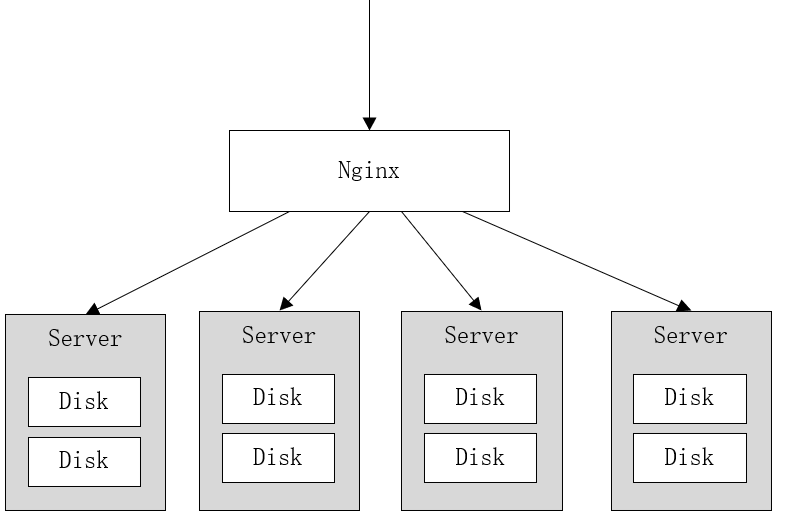

讲义用 8 块盘的例子说明纠删码：4 个数据块 + 4 个校验块，分散存储在同一 erasure set 的各盘中。可用块达到恢复要求时，可以通过算法重建原始数据。

| 概念 | 理解 |
|---|---|
| 数据块 | 对象数据编码后的一部分 |
| 校验块 | 用于恢复丢失 / 损坏块的冗余信息 |
| erasure set | 一组共同参与对象编码和恢复的盘 |
| 读 quorum | 读对象所需的可用条件 |
| 写 quorum | 安全写入所需的可用条件，可能比可恢复数据的要求更严格 |

**校正讲义的简化说法**：不能把“丢失一半仍能恢复”直接推出“丢失一半仍能正常上传和下载”。容忍数量取决于实际数据 / 校验布局、读写 quorum、对象健康状态和版本；可恢复、可读、可写是相关但不同的问题。

讲义本地用四个目录模拟四块盘，再删除目录观察恢复。四个目录在同一台电脑上，只是学习演示，不代表四台独立故障域；电脑整体故障会影响全部目录。直接删除存储目录也不能作为真实业务环境的恢复操作。

本次没有运行安装包、删除目录或实施故障演练。复现课程实验应在隔离的测试数据上确认版本与布局，再观察不同故障下的读写结果。


## 19. Bucket、对象名、访问地址与 MinioClient

对象以 `bucket + objectName` 唯一定位。对象名里的 `/` 是 key 的一部分，控制台可将其显示成目录，不代表数据库 `bucket` 应保存完整路径。

| 例子 | 值 |
|---|---|
| bucket | `mediafiles` |
| objectName / filePath | `2026/10/10/33c643206bb7c08e2cb99b622d7a1b63.png` |
| 相对访问 URL | `/mediafiles/2026/10/10/33c643206bb7c08e2cb99b622d7a1b63.png` |
| SDK endpoint | 课程示例 `http://192.168.101.65:9000` |

课程创建两个桶：`mediafiles` 保存普通文件，`video` 保存视频。原讲义为展示图片将普通文件桶设为公开；实际公开读与授权写是不同权限，私有资源应采用授权访问或带时效的签名 URL。

源码 `MinioConfig` 根据配置创建 SDK 客户端：

```java
@Configuration
public class MinioConfig {
    @Value("${minio.endpoint}")
    private String endpoint;
    @Value("${minio.accessKey}")
    private String accessKey;
    @Value("${minio.secretKey}")
    private String secretKey;

    @Bean
    public MinioClient minioClient() {
        return MinioClient.builder()
            .endpoint(endpoint)
            .credentials(accessKey, secretKey)
            .build();
    }
}
```

要导入 `io.minio.MinioClient`、Spring `Value / Bean / Configuration`。SDK endpoint 是对象 API 地址；控制台地址随部署版本 / 端口设置而变化，不能把登录控制台的 URL 一律当作 SDK endpoint。

返回相对 URL 后，浏览器还需要一个能将这个路径映射到存储的资源域名或反向代理。本日 Gateway 的 `/media/**` 指向业务 API，它不会自动接管 `/mediafiles/**` 图片路径。


## 20. MinIO SDK：上传、下载、删除与完整性

使用 Java SDK `8.4.3`，本地文件上传可调用 `uploadObject`。这里的 `filename` 是**服务端本地路径**，不是前端原文件名。

```java
minioClient.uploadObject(
    UploadObjectArgs.builder()
        .bucket("mediafiles")
        .object("demo/course-cover.png")
        .filename("C:/study-assets/course-cover.png")
        .contentType("image/png")
        .build()
);
```

下载对象与计算摘要的学习片段；需要 IO、NIO、Commons Codec 及 MinIO 参数类型的 imports：

```java
Path downloaded = Paths.get("C:/study-assets/downloaded-cover.png");
try (InputStream in = minioClient.getObject(
        GetObjectArgs.builder()
            .bucket("mediafiles")
            .object("demo/course-cover.png")
            .build())) {
    Files.copy(in, downloaded, StandardCopyOption.REPLACE_EXISTING);
}
try (InputStream in = Files.newInputStream(downloaded)) {
    String downloadedMd5 = DigestUtils.md5Hex(in);
    System.out.println(downloadedMd5);
}
```

```java
minioClient.removeObject(
    RemoveObjectArgs.builder()
        .bucket("mediafiles")
        .object("demo/course-cover.png")
        .build()
);
```

上传 / 删除示例只作用于学习用 `demo/course-cover.png`，本次没有执行。实际使用时换成自己的测试文件；下载的 `REPLACE_EXISTING` 会覆盖目标路径，需明确目标是测试副本。

原文件与下载文件内容的 MD5 一致，可以用于课程中的完整性比较；MD5 不是可靠的防恶意篡改或身份认证机制。也不要普遍把对象 ETag 当作文件 MD5，分段上传、加密等情况可能改变其含义。

MinIO 上传成功只证明对象存储已接收内容，业务数据库记录还需要另行保存。


## 21. 图片上传接口与 DTO

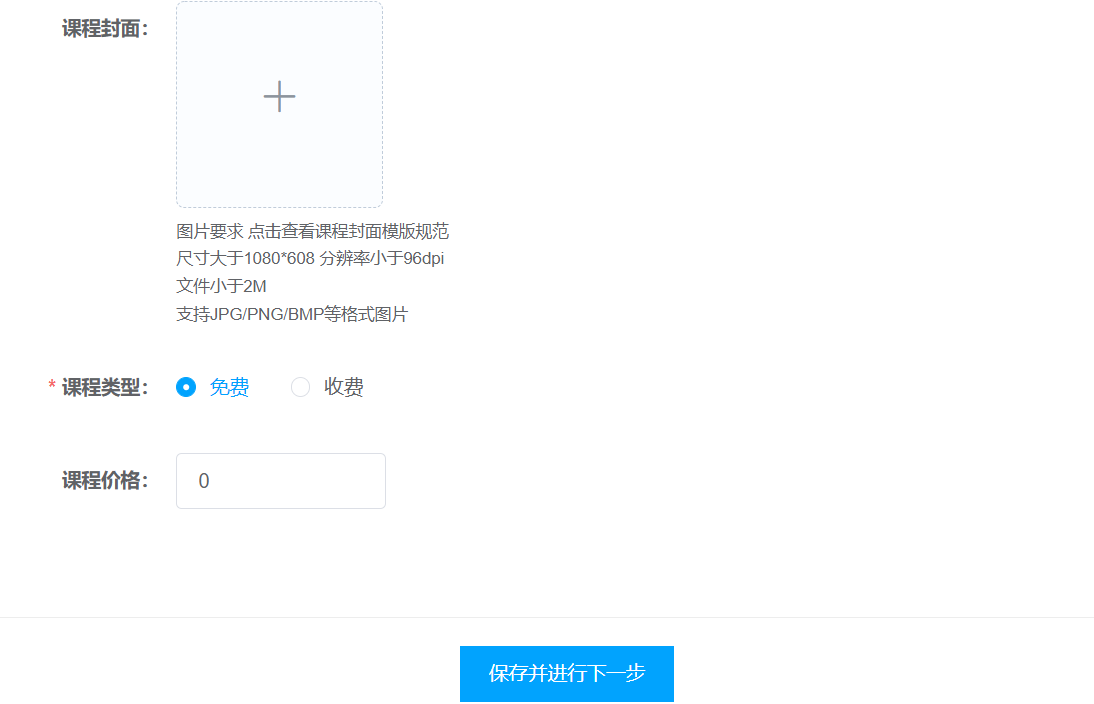

接口完整路径为 `/media/upload/coursefile`，前端以 `multipart/form-data` 提交文件，字段名固定为 `filedata`。不是用 JSON 发送本地路径。

| 项目 | 契约 |
|---|---|
| 请求方法 | 课程实际测试使用 POST |
| 后端直连 | `http://localhost:63050/media/upload/coursefile` |
| 网关入口 | `http://localhost:63010/media/upload/coursefile` |
| 文件字段 | `filedata` |
| Controller 入参 | `MultipartFile` |
| 业务入参 | `companyId + UploadFileParamsDto + localFilePath` |
| 返回对象 | `UploadFileResultDto extends MediaFiles` |

**源码事实**：原 Controller 使用无 method 限定的 `@RequestMapping`；本篇建议改为 `@PostMapping`，把上传接口的请求动词明确限定为 POST。

`UploadFileParamsDto` 包含 `filename`、`fileType`、`fileSize`、`tags`、`username`、`remark`；其中 `fileSize` 为 Long。它用于业务调用，不等于浏览器必须再提交一份同名 JSON。

下面是按当前字段整理的**响应示例**，路径与大小用于说明结构：

```json
{
  "id": "33c643206bb7c08e2cb99b622d7a1b63",
  "companyId": 1232141425,
  "filename": "course-cover.png",
  "fileType": "001001",
  "bucket": "mediafiles",
  "filePath": "2026/10/10/33c643206bb7c08e2cb99b622d7a1b63.png",
  "fileId": "33c643206bb7c08e2cb99b622d7a1b63",
  "url": "/mediafiles/2026/10/10/33c643206bb7c08e2cb99b622d7a1b63.png",
  "status": "1",
  "auditStatus": "002003",
  "fileSize": 248329
}
```

讲义的早期响应把完整路径放进 `bucket` 并带 `timelength`；当前 PO 没有 `timelength`，保存代码将桶与路径分开。本篇以已读源码字段为准。


## 22. Controller：临时文件、参数检查和清理

源码先用 `File.createTempFile` 创建临时文件，再 `filedata.transferTo`，将服务端路径传给 Service。这是适配 `uploadObject(...filename(localFilePath))` 的方式。

原代码没有清理临时文件。反复上传后，临时目录可能持续增长；失败路径也应释放临时资源。

下面是**补充 Controller 方法**，替换原上传方法，并在 Controller 添加 `@Slf4j` 或等效 logger。它补充非空、大小、名称检查与清理，内容格式校验仍需按下一节完善。

```java
@PostMapping(value = "/upload/coursefile",
             consumes = MediaType.MULTIPART_FORM_DATA_VALUE)
public UploadFileResultDto upload(
        @RequestPart("filedata") MultipartFile filedata) throws IOException {
    if (filedata.isEmpty()) {
        throw new XueChengPlusException("上传文件不能为空");
    }
    if (filedata.getSize() > 2L * 1024 * 1024) {
        throw new XueChengPlusException("课程图片不能超过2MB");
    }
    String filename = filedata.getOriginalFilename();
    if (filename == null || filename.trim().isEmpty()) {
        throw new XueChengPlusException("文件名不能为空");
    }

    UploadFileParamsDto params = new UploadFileParamsDto();
    params.setFilename(filename);
    params.setFileSize(filedata.getSize());
    params.setFileType("001001");
    File tempFile = File.createTempFile("course-image-", ".tmp");
    try {
        filedata.transferTo(tempFile);
        return mediaFileService.uploadFile(
            1232141425L, params, tempFile.getAbsolutePath());
    } finally {
        if (!tempFile.delete()) {
            log.warn("临时上传文件清理失败: {}", tempFile.getAbsolutePath());
        }
    }
}
```

2MB 取自讲义封面表单的大小提示，是本篇补充的后端同步限制。请求体还包括 multipart 头部，可以把容器请求上限设得略大于单文件上限：

```yaml
spring:
  servlet:
    multipart:
      max-file-size: 2MB
      max-request-size: 3MB
```

框架限制可能在进入 Controller 前触发异常，需统一返回可理解的错误；网关 / 反向代理也可能有自己的请求大小限制。前端写了 2MB，不代表所有后端默认配置都已一致。

临时文件名随机生成，原文件名仅用于展示与扩展名判断，不能拼成任意本地路径。临时清理失败应记录并安排清理，不用清理异常覆盖原来的上传错误。


## 23. Service：MD5、扩展名、MIME 与对象名

完整项目的 `uploadFile` 流程为：

`读取扩展名 → 推断 MIME → 计算文件 MD5 → 年/月/日目录 → 写 MinIO → 代理调用元信息保存 → 拷贝响应 DTO`。

| 名称 | 示例与作用 |
|---|---|
| 原文件名 | `course-cover.png`，展示名称 |
| 扩展名 | `.png`，参与对象命名与 MIME 推断 |
| 文件 MD5 | 当前代码的 `id / fileId` |
| 默认目录 | `2026/10/10/`，按上传日期组织 |
| 对象名 | `默认目录 + MD5 + 扩展名` |
| MIME | `image/png`，告诉存储 / 浏览器内容类型 |

源码使用 `ContentInfoUtil.findExtensionMatch(extension)`，无法匹配时回退到 `application/octet-stream`。它按扩展名推断，不等于已经识别了真实图片内容。

**需要补充的异常处理**：

- 原 `filename.substring(filename.lastIndexOf("."))` 遇到无扩展名文件会报错；先检查名称与最后一个点，再判断允许格式。
- 原 `getFileMd5` 遇到 IO 异常返回 null；应在上传前抛明确异常，不能生成带 `null` 的对象名或传空主键。
- 上传前确认临时文件存在、可读，文件大小以服务端实际文件为准。
- JPG / PNG / BMP 等允许格式与表单约定一致；扩展名检查后，还需校验实际内容 / 图片解码结果。

图片扩展名检查的**补充片段**：

```java
String filename = uploadFileParamsDto.getFilename();
int dot = filename == null ? -1 : filename.lastIndexOf('.');
if (dot < 0 || dot == filename.length() - 1) {
    throw new XueChengPlusException("图片缺少有效扩展名");
}
String extension = filename.substring(dot).toLowerCase(Locale.ROOT);
if (!Arrays.asList(".jpg", ".jpeg", ".png", ".bmp").contains(extension)) {
    throw new XueChengPlusException("不支持的图片格式");
}
```

需要 `java.util.Locale / Arrays`。这个片段只解释扩展名检查，不能代替文件内容校验。原接口暂把 `fileType` 固定为图片；通用文件接口若扩展到文档、音频，应分别设计类型判断和限制。

原 `addMediaFilesToMinIO` 捕获异常返回 false，`uploadFile` 看到 false 后抛业务异常；本次对象失败时不会继续按成功路径入库。讲义拼写 `exension`、`bucket_files / bucket_Files` 不一致，完整包使用 `extension` 与 `bucket_mediafiles`，照抄片段时须对齐名称。


## 24. 元信息入库：返回数据库实际保存的记录

源码先用 MD5 `selectById`：如果不存在，拷贝上传 DTO 并设置标识、机构、存储位置、时间和状态后插入；如果已存在，直接返回已有记录。

保存字段的核心片段，按源码整理：

```java
MediaFiles mediaFiles = new MediaFiles();
BeanUtils.copyProperties(uploadFileParamsDto, mediaFiles);
mediaFiles.setId(fileMd5);
mediaFiles.setFileId(fileMd5);
mediaFiles.setCompanyId(companyId);
mediaFiles.setBucket(bucket);
mediaFiles.setFilePath(objectName);
mediaFiles.setUrl("/" + bucket + "/" + objectName);
mediaFiles.setCreateDate(LocalDateTime.now());
mediaFiles.setStatus("1");
mediaFiles.setAuditStatus("002003");
int inserted = mediaFilesMapper.insert(mediaFiles);
```

`bucket` 是桶名，`filePath` 是对象名，`url` 是访问引用；三者有不同用途。数据库不应只保存用户原始文件名，再期待靠名称找到唯一对象。

完整代码以 `insert <= 0` 判失败并返回 null，外层看到 null 后抛业务异常。讲义部分示例用了 `insert < 0`，会漏掉影响 0 行的情况；本篇按完整代码说明。

**补充事务规则**：数据库事务方法内部发现业务失败时直接抛异常更明确。若将来一个方法保存多张表，不能先修改一部分表、再正常返回 null，指望调用者在事务已经结束后抛异常还能回滚。

原保存设置的 `auditStatus="002003"` 只是当前代码策略，不能宣称程序已完成审核；若产品要求上传后待审核，应按一致字典与流程修改。

重复文件、跨机构同内容和并发唯一键冲突，不能仅靠“先查再插”解决，见第 27 节。


## 25. 上传事务为什么要缩短

把 `@Transactional` 放在整个上传方法上，会使数据库事务范围覆盖文件处理与网络上传。课程指出，MinIO 上传耗时较长时，可能延长事务、连接占用和锁持有时间。

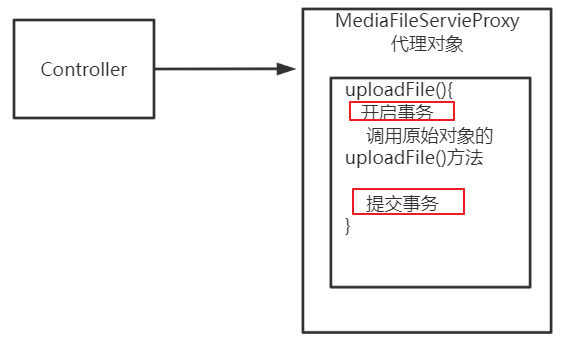

更合适的范围是：先执行文件 IO / MinIO 上传，再调用一个受事务代理控制的数据库保存方法。

| 阶段 | 是否需要数据库事务 |
|---|---|
| 检查文件、计算摘要 | 通常不需要 |
| 向 MinIO 写对象 | JDBC 事务不能管理这次对象写入 |
| 向 `media_files` 写元信息 | 需要按业务原子性控制数据库部分 |
| 返回 DTO | 根据保存结果构造 |

**补充准确性**：事务开启与物理 JDBC 连接何时取得，取决于事务管理器 / 数据源实现；不要把所有文件处理都说成必然持有数据库连接。但把不必要的远程 IO 放进事务边界，仍会增加事务持续时间与资源占用风险。

当前完整包的 `uploadFile` 已去掉 `@Transactional`，只有 `addMediaFilesToDb` 声明事务。关键还在于后者是不是通过 Spring 代理调用，仅把注解挪过去并不够。


## 26. 同类调用为什么绕过事务代理

讲义先移除外层 `uploadFile` 的事务，在内层 `addMediaFilesToDb` 保留 `@Transactional`，人为制造异常验证回滚，发现事务没有生效。

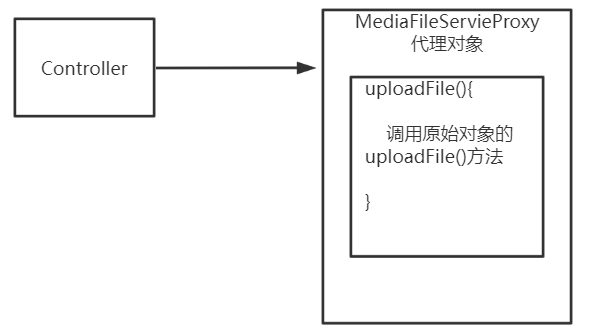

原因是：在同一对象中直接调用另一个方法，调用通常留在目标对象内部，没有重新经过 Spring 事务代理。注解描述规则，但代理需要真正拦截这次调用。

| 调用形式 | 当前代理事务语义 |
|---|---|
| 外部 Bean → 代理 → 带事务的公开方法 | 可以开启 / 加入事务 |
| 无事务外层 → `this.addMediaFilesToDb(...)` | 内层调用通常未经过代理，不单独开启事务 |
| 已有事务外层 → 同类内层 | 内层代码会在外层事务中执行，但内层注解本身未被独立拦截 |
| `currentProxy.addMediaFilesToDb(...)` | 通过代理进入事务方法 |

完整源码采用：

```java
@Autowired
MediaFileService currentProxy;

// uploadFile 中调用，而不是直接 this 调用
MediaFiles mediaFiles = currentProxy.addMediaFilesToDb(
    companyId, fileMd5, uploadFileParamsDto, bucket_mediafiles, objectName);
```

同时把 `addMediaFilesToDb` 声明在 `MediaFileService` 接口中。这个写法体现课程要求；自注入形成的依赖关系在不同框架版本 / 配置下也需确认，不能升级后假定完全相同。

**补充方案**：把数据库保存拆成独立 Bean，外层上传 Service 注入它。这样事务边界和依赖关系更明确，不必依靠同类自注入。

```java
@Service
public class MediaMetadataService {
    @Autowired
    private MediaFilesMapper mediaFilesMapper;

    @Transactional(rollbackFor = Exception.class)
    public MediaFiles save(Long companyId, String fileMd5,
            UploadFileParamsDto params, String bucket, String objectName) {
        MediaFiles existing = mediaFilesMapper.selectById(fileMd5);
        if (existing != null) {
            if (!companyId.equals(existing.getCompanyId())) {
                throw new XueChengPlusException("重复文件的机构归属不一致");
            }
            return existing;
        }
        MediaFiles saved = new MediaFiles();
        BeanUtils.copyProperties(params, saved);
        saved.setId(fileMd5);
        saved.setFileId(fileMd5);
        saved.setCompanyId(companyId);
        saved.setBucket(bucket);
        saved.setFilePath(objectName);
        saved.setUrl("/" + bucket + "/" + objectName);
        saved.setCreateDate(LocalDateTime.now());
        saved.setStatus("1");
        saved.setAuditStatus("002003");
        if (mediaFilesMapper.insert(saved) != 1) {
            throw new XueChengPlusException("保存文件信息失败");
        }
        return saved;
    }
}
```

外层先检查非空机构与合法摘要、执行 MinIO 上传，再从注入的 `MediaMetadataService` 调用 `save`。需要正常导入 Spring、事务、BeanUtils、LocalDateTime 与相关业务类型。此类是补充方案，不是原包中的已完成类。

跨机构重复时本片段选择拒绝，避免返回别的机构记录；它没有完成共享资源模型，也没有解决所有并发唯一键或孤儿对象问题。若元信息方法扩大到多表保存，失败必须在事务内抛出异常。


## 27. MinIO 与数据库一致性，以及 MD5 去重边界

JDBC 事务回滚只能影响数据库，不能自动撤销已经成功上传到 MinIO 的对象。缩短事务不等于解决跨资源一致性。

| 对象写入 | 数据库保存 | 结果与处理 |
|---|---|---|
| 失败 | 未开始 | 返回失败，不生成成功的元信息 |
| 成功 | 成功 | 正常返回 URL，后续保存课程引用 |
| 成功 | 失败 / 回滚 | 可能留下孤儿对象，需要补偿或定期核对清理 |
| 实际成功但响应丢失 | 状态不确定 | 重试前核对对象与记录，不能只凭超时判定没有写入 |

补偿删除只能针对确认由本次操作创建、且没有有效引用的对象，不能删掉其他课程使用的共享文件。课程第四天“删计划绑定不删物理视频”与这里的引用问题是同一条边界。

原代码还有两个重要的重复上传问题：

1. **先上传，再查数据库**。同内容跨日期上传得到新的日期对象路径，但数据库按 MD5 找到旧记录后直接返回旧 URL，新的对象可能无人引用。
2. **全局 MD5 主键与机构归属**。相同内容跨机构上传会命中同一条记录；原代码直接返回已有记录，没有核对 `companyId`，不能称为完善的机构资源隔离。

| 去重维度 | 需要区分 |
|---|---|
| 物理文件去重 | 字节内容相同，可考虑共享一份对象 |
| 机构资源归属 | 每个机构是否拥有该资源、能否查询 / 使用 |
| 业务属性 | 原名称、标签、审核等可能因机构或引用不同 |
| 重试幂等 | 同一次上传重复调用，应取得可解释的一致结果 |

一种更完整的方案是分别维护物理文件与机构资源关系，或让资源主键独立于内容摘要，再明确唯一约束。本日原表结构的 `id` 与 `file_id` 全局唯一，不能只把查询补成“机构 + MD5”就假定不同机构都能插入同摘要记录。

并发“先查不存在 → 都插入”仍会撞唯一键，需要按数据库事务与重试规则处理。MD5 用于课程内容标识，不是访问凭据；知道一个文件哈希不等于有权读取或绑定文件。


## 28. HTTP、课程封面回显与验收

先直接测试媒资，再测试网关，最后在课程页面上传并保存课程。以下文件路径是练习占位路径，需换成自己的测试图片；本次没有执行上传。

```http
### 直连媒资服务上传
POST http://localhost:63050/media/upload/coursefile
Content-Type: multipart/form-data; boundary=StudyBoundary

--StudyBoundary
Content-Disposition: form-data; name="filedata"; filename="course-cover.png"
Content-Type: image/png

< C:/study-assets/course-cover.png
--StudyBoundary--

### 经网关查询图片资源
POST http://localhost:63010/media/files?pageNo=1&pageSize=10
Content-Type: application/json

{
  "filename": "course-cover",
  "fileType": "001001",
  "auditStatus": ""
}

### 经网关回归课程列表
POST http://localhost:63010/content/course/list?pageNo=1&pageSize=10
Content-Type: application/json

{
  "auditStatus": "202002",
  "courseName": ""
}
```

multipart 的 header 中 boundary 与 body 分隔标记必须一致，文件字段必须是 `filedata`，末尾 `--StudyBoundary--` 表示结束。课程包 HTTP 示例未显式写结束标记，本篇补齐，避免依赖工具容错。

经网关上传时，将第一个请求的主机端口改为 `63010`，保留 `/media/upload/coursefile`。查询能返回图片之前，应先补全第 5 节的机构与筛选条件。

保存课程时，新增 / 修改请求的 `pic` 使用上传返回值，其余必填字段沿用第 02 / 03 篇的完整 DTO 契约。不能只发一个 `pic` 字段就假设当前修改课程接口支持局部 PATCH。

| 用例 | 验收结果 |
|---|---|
| 合法图片上传 | MinIO 有对象，`media_files` 有元信息，返回桶 / 路径 / URL |
| 经网关上传 | 方法、路径、字段不变，能路由到可用媒资实例 |
| 页面保存课程后重新打开 | `course_base.pic` 保存返回 URL，封面正常回显 |
| 只上传图片，未保存课程 | 资源可以存在，但课程引用没有更新 |
| 空文件、超限、无扩展名、内容不符 | 返回明确错误，不产生成功引用，临时文件清理 |
| MinIO 不可达 | 对象写入失败，不进入成功入库路径 |
| 数据库失败 | 返回失败，确认数据库回滚与孤儿对象处理 |
| 列表按机构查询 | 只能看到本机构资源，筛选条件生效 |
| 相同内容跨日期 / 跨机构 | 根据选定去重与归属规则处理，不能直接返回他人记录 |
| 多次失败后检查临时目录 | 没有持续积累的临时上传文件 |

排错顺序：

- 404：路由断言、context-path、StripPrefix、前端代理前缀。
- 503：注册名、namespace、group、实例健康与地址可达性。
- 配置读取失败：Data ID 后缀、profile、命名空间 ID、公共 / 应用分组。
- 图片 API 成功但图片不显示：URL 的资源域名 / 代理、桶读取权限、对象是否存在。
- 上传异常：multipart 字段和 boundary、请求大小限制、MinIO endpoint、内容格式。

列表消失 / 封面显示属于页面证据，数据库和对象存储的对应记录属于保存证据，两类都应检查。


## 29. 原始资料与源码差异对照

本篇读取讲义第 1—4 节全部文字及相关原图，核对配套代码与配置。本日完整代码确实包含上传实现，但不代表所有业务与环境已完成。

| 项目 | 原资料 / 源码事实 | 本篇说明或补充 |
|---|---|---|
| 代码包 | 69KB 媒资骨架与 2.4M 完整项目不同 | 上传实现以完整包为准；16 个 POM 静态解析 |
| 列表查询 | `companyId` 与筛选 DTO 未使用 | 补机构过滤、文件名 / 类型 / 审核筛选 |
| 命名空间 | 讲义演示 `dev`，源码 `dev402` | 客户端使用实际 namespace ID，注册与配置分别核对 |
| 系统服务 | 原应用名 `system-service`，尚未接入 Nacos | 与网关 `system-api`、配置 Data ID 统一 |
| 数据库名 | `xc_media / xcplus_media / xc148_media` 混用 | 导入目标和 JDBC URL 一致 |
| 配置包 | 20 个 YAML，包含后续模块 | 导入空间与分组明确，本日只展开相关配置 |
| 路由前缀 | 服务保留 `/content /system /media` | 不随意启用 StripPrefix |
| MinIO 恢复 | 讲义简化成一半盘损坏仍可读写 | 区分恢复、读、写 quorum；单机目录不是独立节点 |
| 上传契约 | 原 `@RequestMapping` 不限定动词 | 补 POST、清理、大小与名称检查 |
| 响应字段 | 早期例子 bucket 为完整路径且有 timelength | 按当前 PO 分离 bucket / filePath / url |
| 上传实现 | MD5、日期对象路径、MinIO、数据库保存 | 明确无扩展名、摘要异常与格式校验缺口 |
| 事务 | 完整包用 `currentProxy` 调用数据库事务 | 解释代理边界，补独立元信息 Bean 方案 |
| 去重 | 全局 MD5，上传后再查、未校验已有记录机构 | 区分物理去重与机构资源归属 |
| 桶与业务记录 | 数据库回滚不撤销对象 | 补偿、引用检查与核对清理需另设计 |

第 5 节大文件断点续传、XXL-JOB 调度与后续视频处理不在本篇实现范围。阅读到相关表或配置，并不能据此认定功能已开发完成。

**复现仍需完成**：准备自己的数据库、Nacos、MinIO 与桶；统一配置和服务名；把补充代码放入正确模块并补齐 imports / 注入；编译与接口测试；核对实际前端代理、资源访问与 CORS；验证数据库和对象异常路径。本篇仅做静态资料与 Notebook 检查。


## 30. 面试提示

**面试提示**：

| 问题 | 回答要点 |
|---|---|
| 媒资服务与内容服务怎样分工？ | 媒资存文件与元信息，内容保存课程 pic / 计划绑定；上传与保存课程是两次请求 |
| 为什么文件不直接存 API 实例本地？ | 多实例共享、扩容和故障时不能依赖某个实例私有磁盘 |
| Nacos 的两个作用？ | 服务注册发现与集中配置；自身不转发业务请求 |
| 配置三要素是什么？ | namespace、group、Data ID；命名空间 ID 与 profile 分开 |
| extension-configs 与 shared-configs 有何区别？ | 前者加载应用的扩展配置，后者加载共享配置；可指定不同分组 |
| 配置刷新开启后所有 Bean 都会更新吗？ | 不会，配置通知、属性更新、Bean / 客户端重建需分别考虑 |
| 网关路由的 Path 与 lb 分别做什么？ | Path 判断匹配，lb 按服务名发现并选择实例 |
| 为什么本项目不用 StripPrefix=1？ | 下游保留 /media 等 context-path，去掉前缀会不匹配 |
| MinIO 是文件系统还是对象存储？ | S3 兼容对象存储，按桶和对象 key 访问 |
| 纠删码可以简单说容忍一半盘吗？ | 取决于布局与读写 quorum；数据恢复能力不等于可继续写入 |
| bucket、filePath、url 有什么区别？ | 桶名、桶内对象名、供客户端使用的访问引用 |
| MultipartFile 为什么转临时文件？ | 适配服务端 SDK 的本地路径上传；成功和失败都要清理 |
| MD5 能保证什么？ | 课程中用于内容标识与摘要比较；不能代替权限或可靠的防恶意篡改机制 |
| 同类方法上的事务为何失效？ | 直接内部调用未重新经过事务代理；可代理调用或拆独立 Bean |
| 为什么不让上传全程占一个数据库事务？ | 远程 IO 不受 JDBC 事务管理，会扩大事务持续时间与资源占用 |
| 数据库回滚会删掉 MinIO 图片吗？ | 不会，要明确补偿、共享引用与孤儿资源清理策略 |
| 全局文件哈希去重有什么业务问题？ | 物理内容可共享，但机构归属、审核、标签等不能直接复用他人记录 |

可以用一次封面上传讲完整链路：“前端通过网关找到媒资服务，服务从 Nacos 取得配置，图片写入 MinIO，元信息通过短事务保存，返回 URL 后再由内容服务保存课程引用”。随后说明机构过滤、事务代理和失败一致性，能把本日架构与实现联系起来。
